# Customer Churn Prediction and Retention Analysis

**Machine Learning course project | Sharif University of Technology**  
Instructor: Ali Sharifi Zarchi

**Team:** Setayesh Heydari, Amir Hossein Shahrabi, Amir Abbas Donyadideh, and Bardia Soltani Moakhar

We study which customers are likely to leave a telecom service, compare classification methods, and use estimated churn risk in an illustrative retention-cost calculation. The analysis uses the IBM Telco Customer Churn sample. The English report is in `reports/report.md` and `reports/customer_churn_report.pdf`.

## 1. Setup and data

Run the cells in order from a fresh Python kernel. Install the repository and its notebook dependencies first with `python -m pip install -e ".[notebook]"`. The first data cell downloads the verified public sample if it is absent. Raw data and trained models stay local.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "telco_churn").exists():
    raise RuntimeError("Open the notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))

import os
os.chdir(ROOT)
import json
import pandas as pd
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from telco_churn.data import DEFAULT_DATA, download_data, load_dataset
from telco_churn.experiment import save_eda, compare_models, evaluate_and_save

In [2]:
if not DEFAULT_DATA.exists():
    download_data()
clean, X, y, audit = load_dataset()
display(pd.Series(audit, name="value").to_frame())
display(clean.drop(columns="customerID").head())

,value
raw_rows,7043
raw_columns,21
duplicate_rows_removed,0
missing_total_charges_removed,11
clean_rows,7032
non_churn,5163
churn,1869
sha256,16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd...


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


`TotalCharges` is stored as text. Eleven blank entries become missing values after numeric conversion. We remove those rows, all of which have zero tenure, leaving 7,032 customers. `customerID` is excluded from prediction. The target is 1 for churn and 0 for no churn.

This complete-charge subset excludes new customers at zero tenure. Median and mode imputers remain in the fitted pipeline for missing input values in the remaining feature columns.

## 2. Split before exploration and fitting

We reserve 30% of the cleaned sample for the final test and use the other 70% for exploratory analysis, feature ranking, model comparison and tuning. The split is stratified by churn with random seed 40. Each five-fold training comparison uses shuffled stratified folds with seed 42. No test label enters a fitted transformation or model-selection rule.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=40, stratify=y
)
display(pd.DataFrame({
    "partition": ["Training", "Test"],
    "customers": [len(y_train), len(y_test)],
    "churned": [int(y_train.sum()), int(y_test.sum())],
    "churn_rate": [y_train.mean(), y_test.mean()],
}))

,partition,customers,churned,churn_rate
0,Training,4922,1308,0.265746
1,Test,2110,561,0.265877


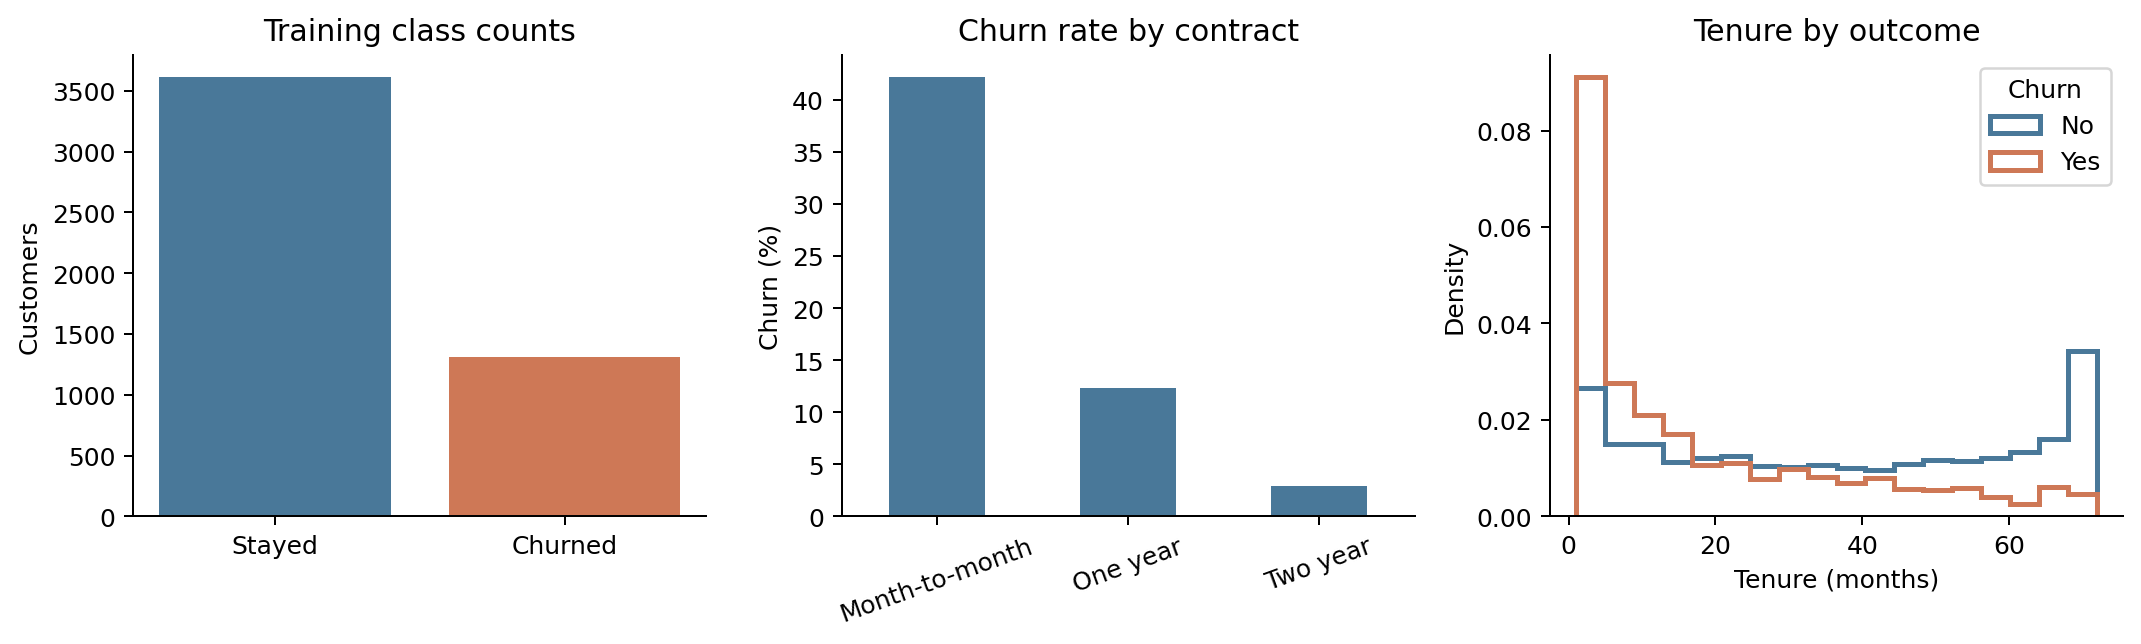

,customers,churn_rate
Contract,,
Month-to-month,2719,0.421846
One year,1028,0.123541
Two year,1175,0.028936


In [4]:
train_frame = clean.loc[X_train.index].copy()
save_eda(train_frame, "reports/figures")
display(Image(filename="reports/figures/training_data_overview.png"))
contract_rates = train_frame.assign(churn=train_frame.Churn.eq("Yes")).groupby("Contract").agg(
    customers=("churn", "size"), churn_rate=("churn", "mean")
)
display(contract_rates)

Most customers in this sample stayed with the service, so accuracy alone can hide missed churn cases. Contract type and tenure show clear differences across outcomes. These are associations in the observed sample; they do not establish that changing a contract or service causes a customer to stay.

## 3. Feature engineering and selection

We add three features calculated independently for each customer:

| Feature | Definition |
| --- | --- |
| `Tenure_Group` | 0-12, 13-24, 25-48, or 49+ months |
| `Avg_Monthly_Spend` | `TotalCharges / (tenure + 1)` |
| `Service_Count` | Number of seven add-on services recorded as `Yes` |

The spending ratio summarizes cumulative charges relative to tenure. It does not measure a spending trend because monthly history is unavailable.

Within each training fold, numerical values are imputed and standardized, and categorical values are imputed and one-hot encoded. We rank encoded features using a normalized chi-squared/ANOVA filter score, absolute Lasso coefficients, and random-forest impurity importance. The 12 features with the lowest average rank are retained. Lasso is used only for ranking a binary target. The statistical scores are screening heuristics; we do not interpret them as causal effects or adjusted significance tests.

In [5]:
display(X_train[["tenure", "Tenure_Group", "TotalCharges", "Avg_Monthly_Spend", "Service_Count"]].head())

,tenure,Tenure_Group,TotalCharges,Avg_Monthly_Spend,Service_Count
983,1,0-12 months,86.60,43.300000,2
6565,61,49+ months,6375.20,102.825806,5
2212,10,0-12 months,225.85,20.531818,0
2526,1,0-12 months,19.40,9.700000,0
2751,19,13-24 months,434.80,21.740000,0


## 4. Class imbalance, candidate models and tuning

We compare logistic regression with no rebalancing, balanced class weights, and SMOTE. We also fit KNN, random forest, gradient boosting, and a soft-voting ensemble of logistic regression, random forest and gradient boosting.

SMOTE is applied only within each fitting fold after preprocessing and feature selection. It never resamples a validation or test partition. With one-hot inputs, ordinary SMOTE can create fractional indicator values; class weighting provides a comparison that avoids that issue.

The final two candidates tune logistic regression and random forest with SMOTE. We select the model with the highest mean five-fold recall among those with mean F1 at least 0.50, breaking ties by F1 and then model name. Search scores are development results, and can be optimistic after parameter selection. The held-out test provides a separate evaluation for this experiment.

In [6]:
selected, selected_name, comparison, folds, searches = compare_models(
    X_train, y_train, cache_dir=".cache/pipeline", n_jobs=1
)
display(comparison[["model", "cv_recall", "cv_recall_std", "cv_precision", "cv_f1", "cv_roc_auc", "selected"]].round(4))
print("Selected model:", selected_name)
print(json.dumps(searches, indent=2))

Cross-validation: Logistic regression
Cross-validation: Logistic regression (balanced)
Cross-validation: Logistic regression + SMOTE
Cross-validation: KNN
Cross-validation: Random forest
Cross-validation: Gradient boosting
Cross-validation: Soft voting
Grid search: Tuned logistic regression + SMOTE
Grid search: Tuned random forest + SMOTE
Selected model: Tuned random forest + SMOTE
{
  "Tuned logistic regression + SMOTE": {
    "best_parameters": {
      "model__C": 1.0,
      "model__l1_ratio": 0.0,
      "model__solver": "lbfgs"
    },
    "combinations": 6
  },
  "Tuned random forest + SMOTE": {
    "best_parameters": {
      "model__criterion": "entropy",
      "model__max_depth": 4,
      "model__max_features": "sqrt",
      "model__n_estimators": 100
    },
    "combinations": 8
  }
}


,model,cv_recall,cv_recall_std,cv_precision,cv_f1,cv_roc_auc,selected
0,Tuned random forest + SMOTE,0.8081,0.0221,0.5073,0.6230,0.8365,True
1,Logistic regression (balanced),0.7989,0.0117,0.5144,0.6258,0.8370,False
2,Tuned logistic regression + SMOTE,0.7966,0.0106,0.5172,0.6270,0.8370,False
3,Logistic regression + SMOTE,0.7966,0.0106,0.5172,0.6270,0.8370,False
4,Gradient boosting,0.5137,0.0348,0.6494,0.5730,0.8366,False
5,KNN,0.5022,0.0655,0.6170,0.5523,0.8187,False
6,Soft voting,0.4961,0.0408,0.6546,0.5636,0.8398,False
7,Logistic regression,0.4877,0.0402,0.6519,0.5572,0.8371,False
8,Random forest,0.4831,0.0453,0.6552,0.5551,0.8377,False


In [7]:
ranking = selected.named_steps["select"].ranking_frame(
    selected.named_steps["preprocess"].get_feature_names_out()
)
display(ranking)
print("Selected features:", ranking.loc[ranking.selected, "feature"].tolist())

Selected features: ['Contract_Two year', 'InternetService_Fiber optic', 'tenure', 'PaymentMethod_Electronic check', 'TotalCharges', 'MonthlyCharges', 'Contract_One year', 'Tenure_Group_49+ months', 'Avg_Monthly_Spend', 'InternetService_No', 'TechSupport_Yes', 'PaperlessBilling_Yes']


,feature,filter_score,lasso_abs_coefficient,rf_importance,average_rank,selected
0,Contract_Two year,0.859618,0.046218,0.093410,3.333333,True
1,InternetService_Fiber optic,0.723554,0.114710,0.069368,4.000000,True
2,tenure,0.737375,0.022826,0.157449,5.333333,True
3,PaymentMethod_Electronic check,0.842058,0.034428,0.063381,6.333333,True
4,TotalCharges,0.219068,0.079598,0.106829,8.333333,True
5,MonthlyCharges,0.185660,0.113366,0.073176,9.000000,True
6,Contract_One year,0.259873,0.038457,0.032575,10.333333,True
7,Tenure_Group_49+ months,0.617512,0.003103,0.050977,11.666667,True
8,Avg_Monthly_Spend,0.022716,0.211859,0.071590,12.000000,True
9,InternetService_No,0.464727,0.053364,0.008001,12.000000,True


## 5. Test evaluation and probability calibration

We freeze model choice before evaluating the test split. Classification uses the selected classifier's default 0.50 threshold. We report churn-class precision, recall, F1, ROC-AUC, average precision, and the confusion matrix, alongside an always-stay baseline.

For the retention scenario, a separate sigmoid-calibrated version of the same model is fitted using three stratified folds of the training data at natural class prevalence. The scenario uses its calibrated probabilities. This adds an explicit probability check; calibration is not a guarantee of accurate risk estimates for a different customer population.

Selected using training CV: Tuned random forest + SMOTE


,Selected classifier,Always-stay baseline
accuracy,0.7370,0.7341
precision,0.5032,0.0000
recall,0.8396,0.0000
f1,0.6293,0.0000
roc_auc,0.8547,0.5000
average_precision,0.6757,0.2659
brier_score,0.1650,0.2659


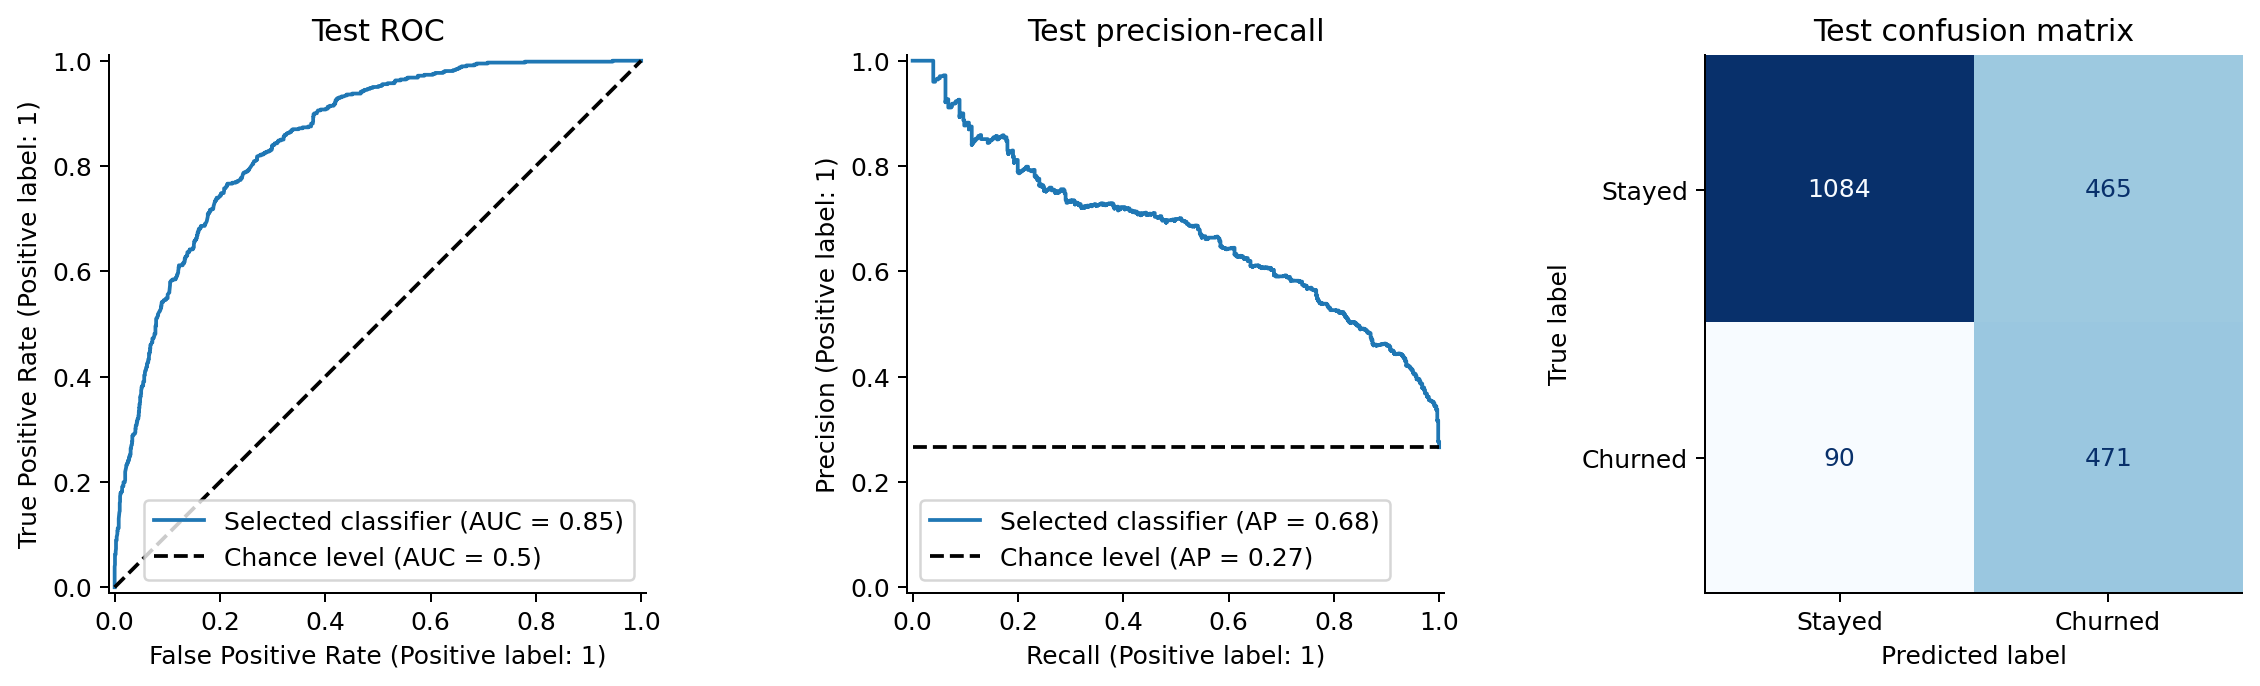

In [8]:
summary = evaluate_and_save(
    selected, selected_name, comparison, folds, searches,
    X_train, X_test, y_train, y_test, audit, "reports"
)
display(pd.DataFrame({
    "Selected classifier": {k: v for k, v in summary["test_metrics"].items() if k != "confusion_matrix"},
    "Always-stay baseline": {k: v for k, v in summary["dummy_test_metrics"].items() if k != "confusion_matrix"},
}).round(4))
display(Image(filename="reports/figures/holdout_evaluation.png"))

,score
uncalibrated_brier,0.165003
calibrated_brier,0.132739
calibrated_roc_auc,0.855344


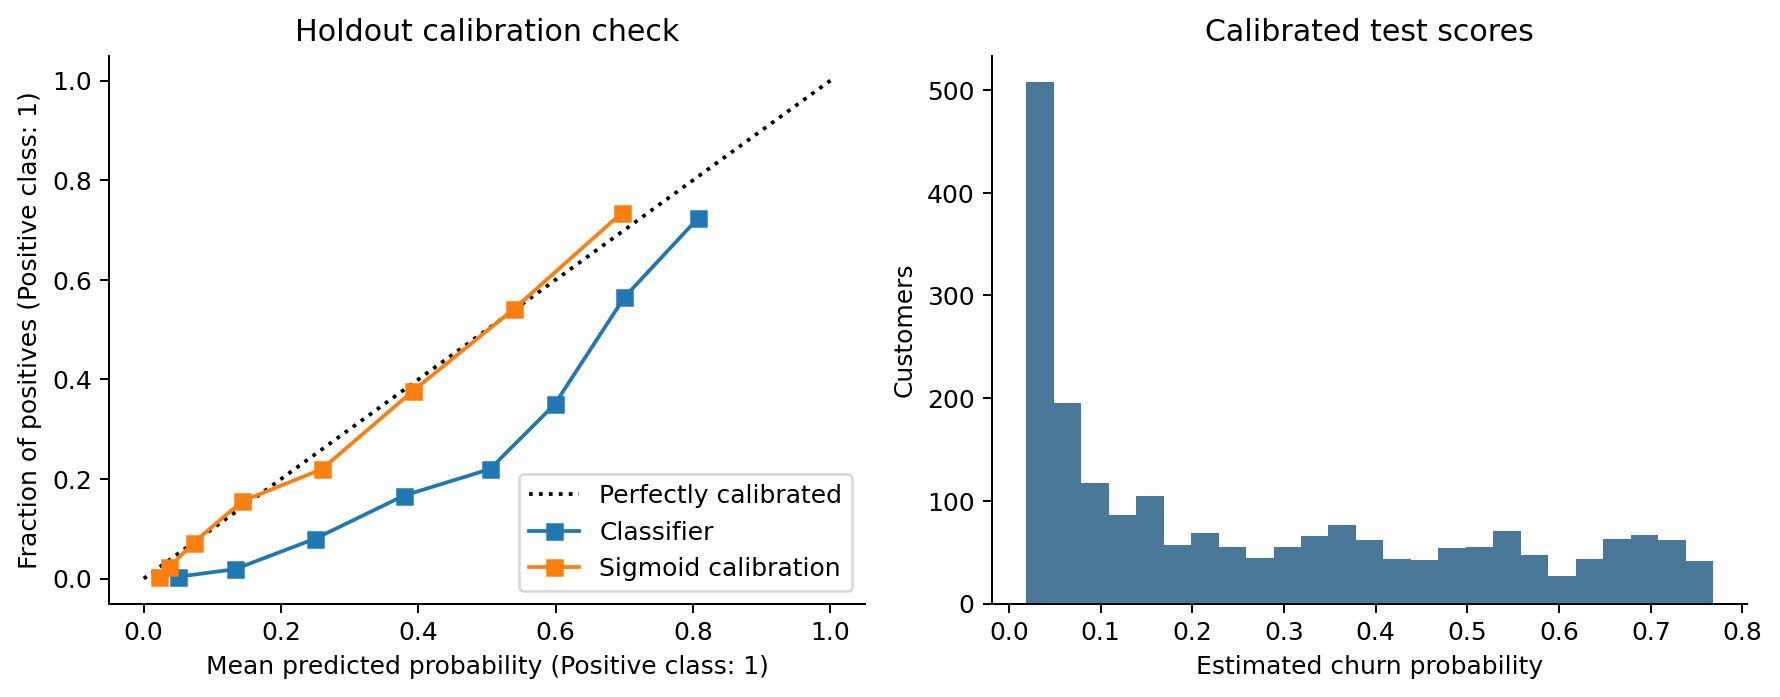

In [9]:
display(pd.Series(summary["calibration"], name="score").to_frame())
display(Image(filename="reports/figures/probability_calibration.png"))

## 6. Illustrative retention decisions

Let `p` be calibrated churn probability, `L` the loss if a customer leaves, `c` intervention cost, and `s` the fraction of otherwise-churning customers retained by that action.

- No action: expected loss = `p * L`.
- Intervention: expected loss = `p * (1 - s) * L + c`.
- Incremental savings versus no action = `p * s * L - c`.

We assume a USD 500 churn loss, USD 50/100 action costs, and 30%/60% success rates. Costs apply to every targeted customer. These are illustrative inputs, not estimates from the dataset. All actions use the same loss baseline.

Under these particular assumptions, the low-cost action is never uniquely optimal. The high-cost action's savings are exactly twice the low-cost action's savings. Below `p = 1/3`, no action wins; above `1/3`, the high-cost action wins. At the boundary the actions tie, and the implementation selects no action. A zero count for low-cost actions follows from the assumptions.

,strategy,expected_loss,expected_savings_vs_none
0,none,285270.51,0.00
1,low_all,305189.35,-19918.85
2,high_all,325108.20,-39837.70
3,targeted,235592.62,49677.88


,action,customers
0,none,1322
1,low,0
2,high,788


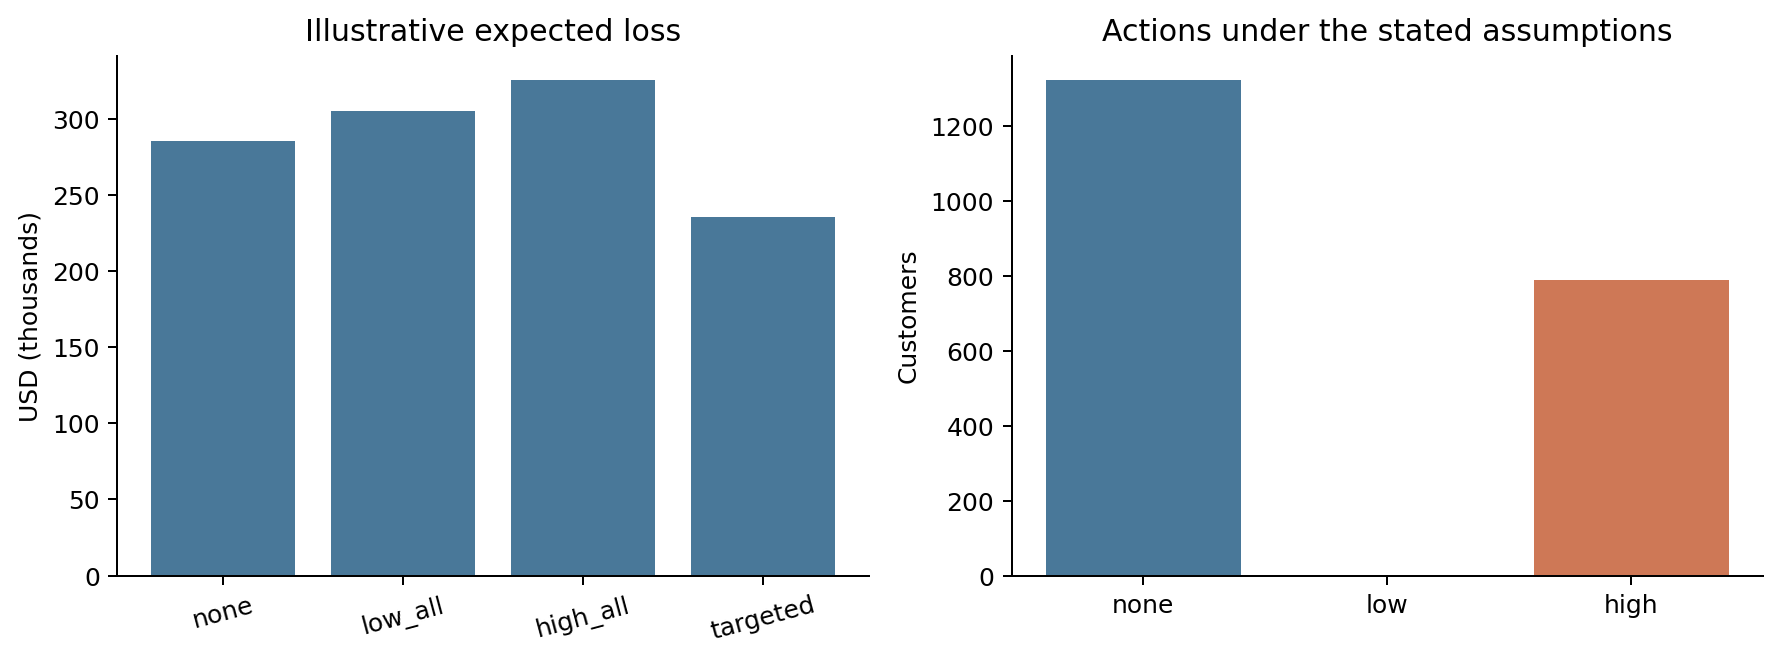

In [10]:
scenario = pd.read_csv("reports/results/retention_scenario.csv")
action_counts = pd.read_csv("reports/results/retention_action_counts.csv")
display(scenario.round(2))
display(action_counts)
display(Image(filename="reports/figures/retention_scenario.png"))

## 7. Interpretation and limits

Recall measures how many observed churn cases we identify; precision measures how many flagged customers actually churned. Choosing high recall increases the number of customers to contact, so campaign capacity matters.

The dataset is a public customer snapshot used during coursework. A random holdout does not measure future performance, and this is not independent external validation. Feature ranks can change with the split; correlated billing fields share information. SMOTE can distort score calibration and produce fractional categorical indicators. The report separates classifier metrics from the calibrated probabilities used in the scenario.

The dataset has no intervention outcomes. The scenario estimates neither causal treatment effects nor realized profit. A retention campaign would need validated costs, treatment-response experiments, probability checks on current customers, and a budget constraint.

Aggregate tables and figures are saved under `reports/`; the local model bundle is saved under `models/`. Source-row split indices are included for reproducibility. Customer-level predictions are not included in the repository.